# Sampling Simulator Brown Bear

Este notebook se utilizará como plantilla de prueba para los el código en main.r



## Imports
Por defecto importamos dplyr. Los demás paquetes se llamaran individualmente

In [112]:
library(dplyr)
library(data.table)


Attaching package: ‘dplyr’

The following objects are masked from ‘package:stats’:

    filter, lag

The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union

data.table 1.16.2 using 4 threads (see ?getDTthreads).  Latest news: r-datatable.com

Attaching package: ‘data.table’

The following objects are masked from ‘package:dplyr’:

    between, first, last



## Inputs
Los inputs que el usuario debería hacer

In [58]:
TIPO = "MSA" # Tipo de muestra: simple al azar
N = 1000  # tamaño poblacional
n = 10    # tamaño muestral




#Valores por defecto en caso de error
N_POR_DEFECTO = 1000

#Valores por defecto
MEDIANA_INGRESOS = 2800000
MEDIA_INGRESOS = MEDIANA_INGRESOS/ log(2) # calcula la media en base a la mediana de una distribución exponencial. Usa la EPH como fuente
ERROR_INGRESOS = 0.05    # ruido. Error promedio, porcentual, a aplicarse sobre los ingresos

## Funciones

In [ ]:
generar_poblacion = function(N){
  # Genera una matriz con un id hogar y una variable escondida.
  # Inputs:
  # N -- tamaño poblacional
  # Outputs:
  # Matrix Nx3 con las variables id_hogar y var_hidden_1 
  # Manejo de errores:
  # N decimal: trunca (floor())
  # N negativo, cero o NA: utiliza N_POR_DEFECTO
  
  #Validacion
  if(is.na(N) | N < 1  ){
    print("N invalido, pasando a valores por defecto: N = 1000")
    N = N_POR_DEFECTO
  } else if(N > floor(N)){
    print("N debe ser un número entero, se redondea a", floor(N))
    N = floor(N)
  }
  

  output = data.table(
    id_hogar = seq_len(N),
    var_hidden_1 = runif(N)
  )
  return(output)

}

crea_variables = function(matriz){
  # Genera variables manifestas a través de las variables escondidas
  # input una matriz donde al menos una columna tenga el nombre "var_hidden_1"
  # output misma matriz, pero con una columna adicional llamada "ingresos"
  # generación de la variable 'ingresos': se utiliza la distribución exponencial, partiendo de los ingresos medianos por defecto
  # Manejo de errores:
  # si no encuentra 'var_hidden_1' devuelve una columna con la mediana.

  N = nrow(matriz)
  ruido = rnorm( n = N, mean = 1  ,  sd = ERROR_INGRESOS) #error porcentual a la variable ingresos

  if ("var_hidden_1" %in% colnames(matriz)) {
    matriz[, Ingresos :=
      qexp(var_hidden_1, rate = 1/MEDIA_INGRESOS) * ruido
    ]
  } else {
    warning("var_hidden_1 no encontrada, se reemplaza por la media")
    matriz[, Ingresos :=
      MEDIA_INGRESOS * ruido
    ]

  }

  return(matriz)
}


asignar_probabilidad_de_seleccion = function(matriz, n=n, tipo = "MSA"){
  # Añade una columna a matriz que contiene la probabilidad de seleccion n/N
  # inputs:
  # matriz -- matriz que contiene la población
  # n -- tamaño de la muestra
  # tipo -- tipo de muestra, por defecto MSA
  # output:
  # matriz con la población más una columna adicional con la probabilidad de seleccion 'prob_seleccion'
  # Manejo de errores:
  # n menor a uno o mayor a N -- convierte en N
  # n decimal -- trunca (floor())
  # tipo no considerado en la formula -- convierte a MSA
  N = nrow(matriz)
  
  if(n<1){
    print( "n debe ser al menos 1, se convierte a censo n=N")
    n = N
  }
  if(n>N){
    print( "n debe ser a lo sumo igual a N, se convierte a censo n=N")
    n = N
  }
  if(n>floor(n)){
    print("n debe ser un número entero, se trunca")
    n = floor(n)
  }
  if( !(tipo %in% c("MSA") ) ){
    print("tipo de muestreo desconocido, se utilizará muestreo simple al azar")
    tipo = 'MSA'
  }  
  
  matriz[, Prob_seleccion :=
      rep( n/N, times=N)
    ]
  

  return(matriz)



}

seleccionar_muestra = function(matriz, n=n , tipo = "MSA"){
  #Selecciona una muestra simple al azar. La guarda como una columna 'seleccionada' con valor 1 si fue seleccionada y 0 si no.
  # inputs:
  # matriz -- matriz con la poblacion
  # n -- tamaño de la muestra
  # tipo -- tipo de muestreo a utilizar, por defecto MSA
  # Manejo de errores:
  # n mayor a N, n menor a 1 -- se reemplaza por N
  # n decimal -- trunca (floor())
  # tipo no considerado en la formula -- convierte a MSA 
  N = nrow(matriz)
  
  if(n<1){
    print( "n debe ser al menos 1, se convierte a censo n=N")
    n = N
  }
  if(n>N){
    print( "n debe ser a lo sumo igual a N, se convierte a censo n=N")
    n = N
  }
  if(n>floor(n)){
    print("n debe ser un número entero, se trunca")
    n = floor(n)
  }
  if( !(tipo %in% c("MSA") ) ){
    print("tipo de muestreo desconocido, se utilizará muestreo simple al azar")
    tipo = 'MSA'
  } 

  seleccion = sample.int(N, n)


  return(matriz[seleccion,])
}

estimar_total = function(matriz, tipo = "MSA"){
  # Estima el total de ingresos, usando las columnas seleccion y prob_seleccion, es decir el estimador de horvit thompson
  # total = ingresos * seleccion * 1 / prob_seleccion
  # inptus:
  # matriz -- poblacion con las columnas ingreso, prob_seleccion y seleccion
  # tipo -- tipo de muestreo, por defecto MSA
  # outputs
  # estimacion del total
  # Manejo de errores:
  # seleccion debe ser 0 o 1 -- utiliza un censo



  total =sum( matriz$Ingresos  / matriz$Prob_seleccion  )
  return(total)
}





In [129]:
install.packages(c("shiny", "data.table", "ggplot2"))

Installing packages into ‘C:/Users/User/AppData/Local/R/win-library/4.4’
(as ‘lib’ is unspecified)
also installing the dependencies ‘httpuv’, ‘otel’, ‘promises’, ‘sourcetools’, ‘xtable’


  There are binary versions available but the source versions are later:
        binary source needs_compilation
otel     0.2.0  0.3.0             FALSE
shiny   1.13.0 1.14.0             FALSE
ggplot2  4.0.3  4.0.4             FALSE



trying URL 'https://cran.rstudio.com/bin/windows/contrib/4.4/httpuv_1.6.17.zip'
Content type 'application/zip' length 1048781 bytes (1.0 MB)
downloaded 1.0 MB

trying URL 'https://cran.rstudio.com/bin/windows/contrib/4.4/promises_1.5.0.zip'
Content type 'application/zip' length 1703916 bytes (1.6 MB)
downloaded 1.6 MB

trying URL 'https://cran.rstudio.com/bin/windows/contrib/4.4/sourcetools_0.1.7-2.zip'
Content type 'application/zip' length 128275 bytes (125 KB)
downloaded 125 KB

trying URL 'https://cran.rstudio.com/bin/windows/contrib/4.4/xtable_1.8-8.zip'
Content type 'application/zip' length 762106 bytes (744 KB)
downloaded 744 KB



package ‘httpuv’ successfully unpacked and MD5 sums checked
package ‘promises’ successfully unpacked and MD5 sums checked
package ‘sourcetools’ successfully unpacked and MD5 sums checked
package ‘xtable’ successfully unpacked and MD5 sums checked

The downloaded binary packages are in
	C:\Users\User\AppData\Local\Temp\RtmpGQrZsT\downloaded_packages
installing the source packages ‘otel’, ‘shiny’, ‘ggplot2’



trying URL 'https://cran.rstudio.com/src/contrib/otel_0.3.0.tar.gz'
Content type 'application/x-gzip' length 81535 bytes (79 KB)
downloaded 79 KB

trying URL 'https://cran.rstudio.com/src/contrib/shiny_1.14.0.tar.gz'
Content type 'application/x-gzip' length 2739936 bytes (2.6 MB)
downloaded 2.6 MB

trying URL 'https://cran.rstudio.com/src/contrib/ggplot2_4.0.4.tar.gz'
Content type 'application/x-gzip' length 6357378 bytes (6.1 MB)
downloaded 6.1 MB



* installing *source* package 'otel' ...
** package 'otel' successfully unpacked and MD5 sums checked
** using staged installation
** R
** inst
** byte-compile and prepare package for lazy loading
** help
*** installing help indices
** building package indices
** testing if installed package can be loaded from temporary location
** testing if installed package can be loaded from final location
** testing if installed package keeps a record of temporary installation path
* DONE (otel)
* installing *source* package 'ggplot2' ...
** package 'ggplot2' successfully unpacked and MD5 sums checked
** using staged installation
** R
** data
*** moving datasets to lazyload DB
** inst
** byte-compile and prepare package for lazy loading
** help
*** installing help indices
*** copying figures
** building package indices
** installing vignettes
** testing if installed package can be loaded from temporary location
** testing if installed package can be loaded from final location
** testing if install


The downloaded source packages are in
	‘C:\Users\User\AppData\Local\Temp\RtmpGQrZsT\downloaded_packages’


In [127]:
N_SIMULACIONES = 100
N=10000000
n=1000
resultados = matrix(0, nrow=N_SIMULACIONES, ncol=2)
colnames(resultados) = c("estimador", "error")

pob = generar_poblacion(N=N) |> 
  crea_variables() |> 
  asignar_probabilidad_de_seleccion(n=n) 

real = sum(pob$Ingresos)


for(sim in 1:N_SIMULACIONES){
  if(sim %% 10 == 0) {print(sim)}

  muestra = pob |> seleccionar_muestra( n=n)

  estimado = estimar_total(muestra)
  error = (estimado - real)/real  

  resultados[sim,"estimador"] = estimado
  resultados[sim,"error"] = error




  




}




[1] 10
[1] 20
[1] 30
[1] 40
[1] 50
[1] 60
[1] 70
[1] 80
[1] 90
[1] 100


In [126]:
object.size(muestra)

28001768 bytes

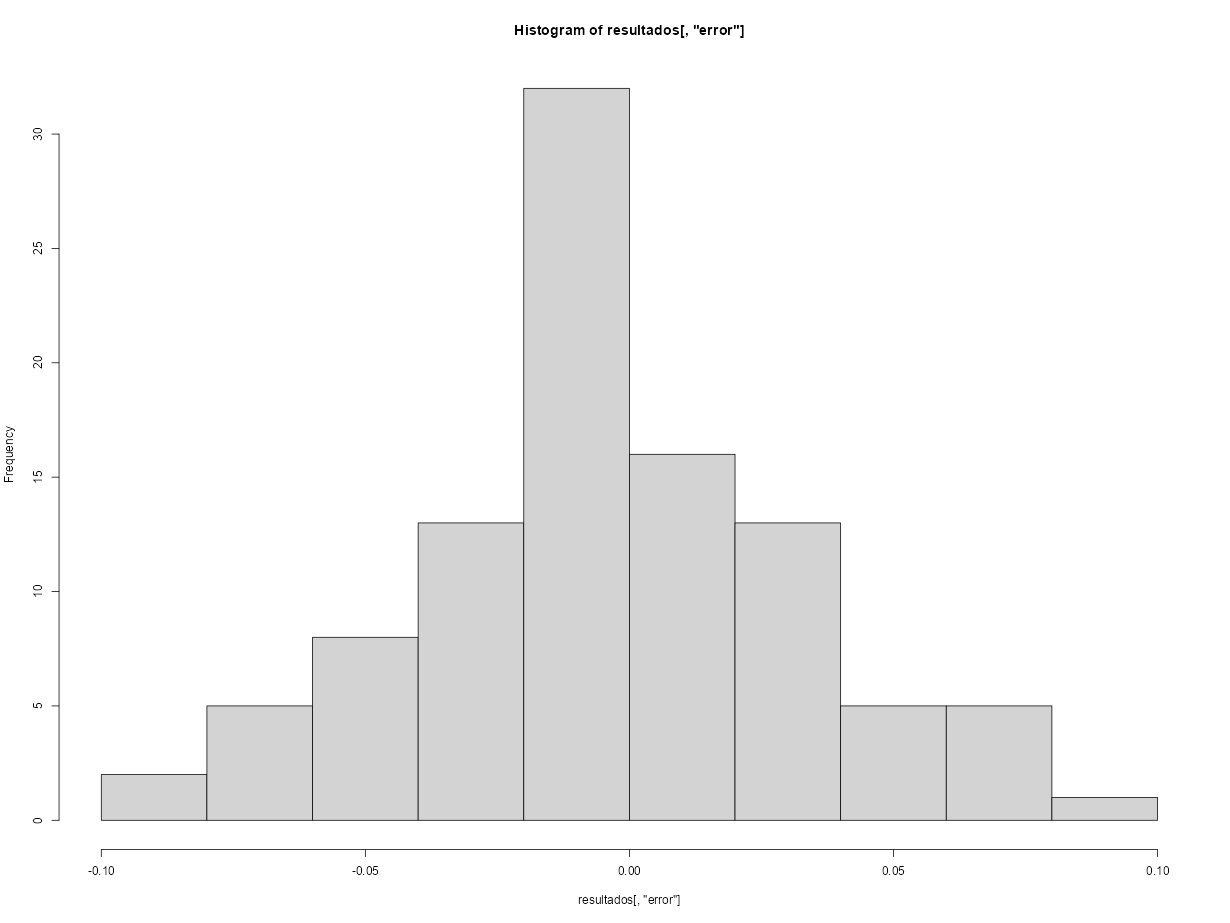

In [128]:
hist(resultados[,"error"])